# Modelos base TF-IDF para MAP

**Objetivo.** Comparar modelos lineales reproducibles para ordenar etiquetas compuestas `Category[:Misconception]` a partir de la pregunta, la opción seleccionada y la explicación estudiantil.

**Criterio principal.** Seleccionar por MAP@3 y acompañar la decisión con top-3 accuracy, macro-F1, accuracy y una prueba separada con preguntas no vistas.

## Diseño experimental

- Se retiran 736 duplicados exactos, sin descartar respuestas únicamente por ser atípicas.
- La entrada concatena marcadores de **pregunta**, **opción** y **explicación**.
- TF-IDF combina bigramas de palabras con n-gramas de caracteres; se ajusta solo con entrenamiento.
- Se comparan prior ingenuo, Complement Naive Bayes, regresión logística con SGD y SVM lineal.
- La evaluación principal usa una partición estratificada 80/20. Una segunda prueba excluye preguntas completas mediante agrupamiento por `QuestionId`.
- Semilla fija: 42.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
SCRIPT = ROOT / 'notebooks' / 'entrenar_modelos_base_MAP.py'
RESULTS = ROOT / 'report' / 'model_results'
ASSETS = ROOT / 'report' / 'assets' / 'modelos'
SCRIPT.exists(), 'raíz del repositorio'

(True, 'raíz del repositorio')

## Ejecución reproducible

El módulo conserva toda la lógica de preparación, entrenamiento, evaluación y exportación. Ejecutarlo vuelve a construir los resultados desde `data/train.csv`.

In [2]:
import runpy
module = runpy.run_path(str(SCRIPT), run_name='map_modeling')
module['main']()


Prior ingenuo                MAP@3=0.5404  macro-F1=0.0101  accuracy=0.4026


Complement Naive Bayes       MAP@3=0.6574  macro-F1=0.2154  accuracy=0.5326


Regresión logística (SGD)    MAP@3=0.8470  macro-F1=0.4790  accuracy=0.7498


SVM lineal                   MAP@3=0.8824  macro-F1=0.4982  accuracy=0.8063



Modelo seleccionado: SVM lineal
{
  "fecha_ejecucion": "2026-10-12T14:30:37.027401-06:00",
  "semilla": 42,
  "python": "3.13.1",
  "pandas": "2.2.3",
  "scikit_learn": "1.8.0",
  "filas_originales": 36696,
  "filas_modelado_sin_duplicados_exactos": 35960,
  "duplicados_exactos_retirados": 736,
  "n_clases": 65,
  "n_entrenamiento": 28769,
  "n_validacion": 7191,
  "n_caracteristicas_tfidf": 41763,
  "densidad_tfidf_pct": 0.708125211535505,
  "tiempo_vectorizacion_s": 26.541117399930954,
  "mejor_modelo": "SVM lineal",
  "validacion_estratificada": {
    "modelo": "SVM lineal",
    "map_at_3": 0.8823529411764706,
    "top3_accuracy": 0.968571825893478,
    "macro_f1": 0.49819214154420444,
    "accuracy": 0.8062856348213044,
    "tiempo_entrenamiento_s": 39.71736890007742,
    "n_clases_modelo": 65
  },
  "validacion_preguntas_no_vistas": {
    "modelo": "SVM lineal",
    "map_at_3": 0.4293629786483148,
    "top3_accuracy": 0.5889888830068819,
    "macro_f1": 0.029301835123903514,
    

In [3]:
print('Entrenamiento, evaluación y exportación finalizados.')

Entrenamiento, evaluación y exportación finalizados.


## Comparación de modelos

Todas las métricas siguientes proceden de la misma partición de validación y de la misma representación TF-IDF.

In [4]:
metrics = pd.read_csv(RESULTS / 'comparacion_modelos.csv')
metrics.style.format({
    'map_at_3': '{:.4f}',
    'top3_accuracy': '{:.4f}',
    'macro_f1': '{:.4f}',
    'accuracy': '{:.4f}',
    'tiempo_entrenamiento_s': '{:.2f}',
}).hide(axis='index')

modelo,map_at_3,top3_accuracy,macro_f1,accuracy,tiempo_entrenamiento_s,n_clases_modelo
SVM lineal,0.8824,0.9686,0.4982,0.8063,39.72,65
Regresión logística (SGD),0.8470,0.9619,0.4790,0.7498,16.44,65
Complement Naive Bayes,0.6574,0.8117,0.2154,0.5326,1.40,65
Prior ingenuo,0.5404,0.7266,0.0101,0.4026,0.03,65


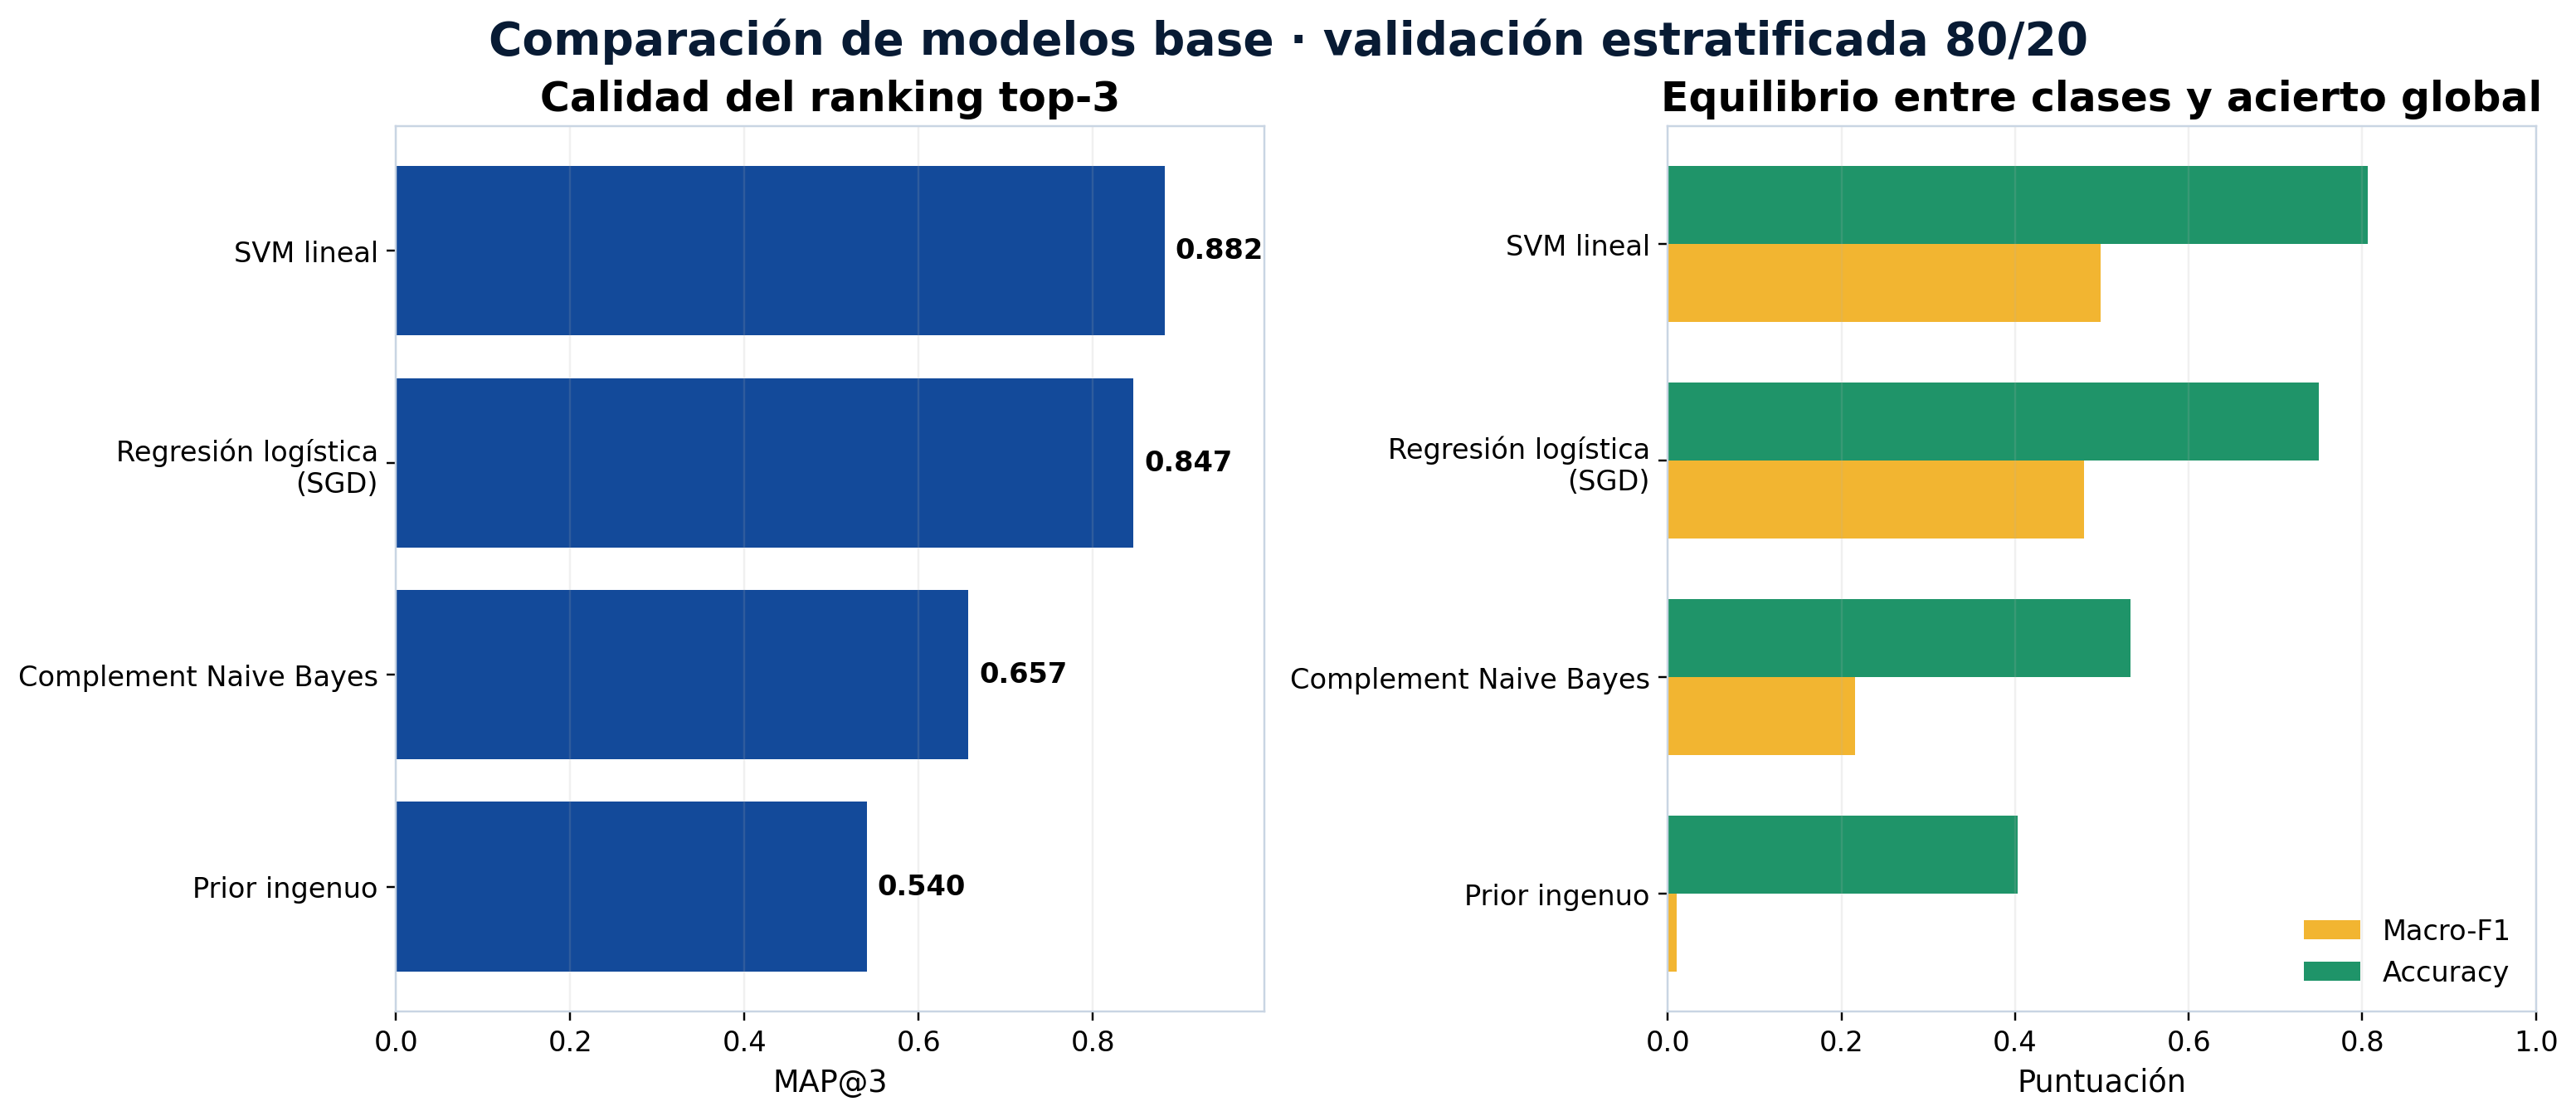

In [5]:
display(Image(filename=str(ASSETS / 'comparacion_modelos_base.png'), width=1100))

## Generalización y desempeño por clase

La evaluación con preguntas conocidas mide clasificación de explicaciones nuevas dentro de contextos ya observados. La prueba agrupada es más exigente: retira preguntas completas y revela cuánto depende el modelo del contexto específico.

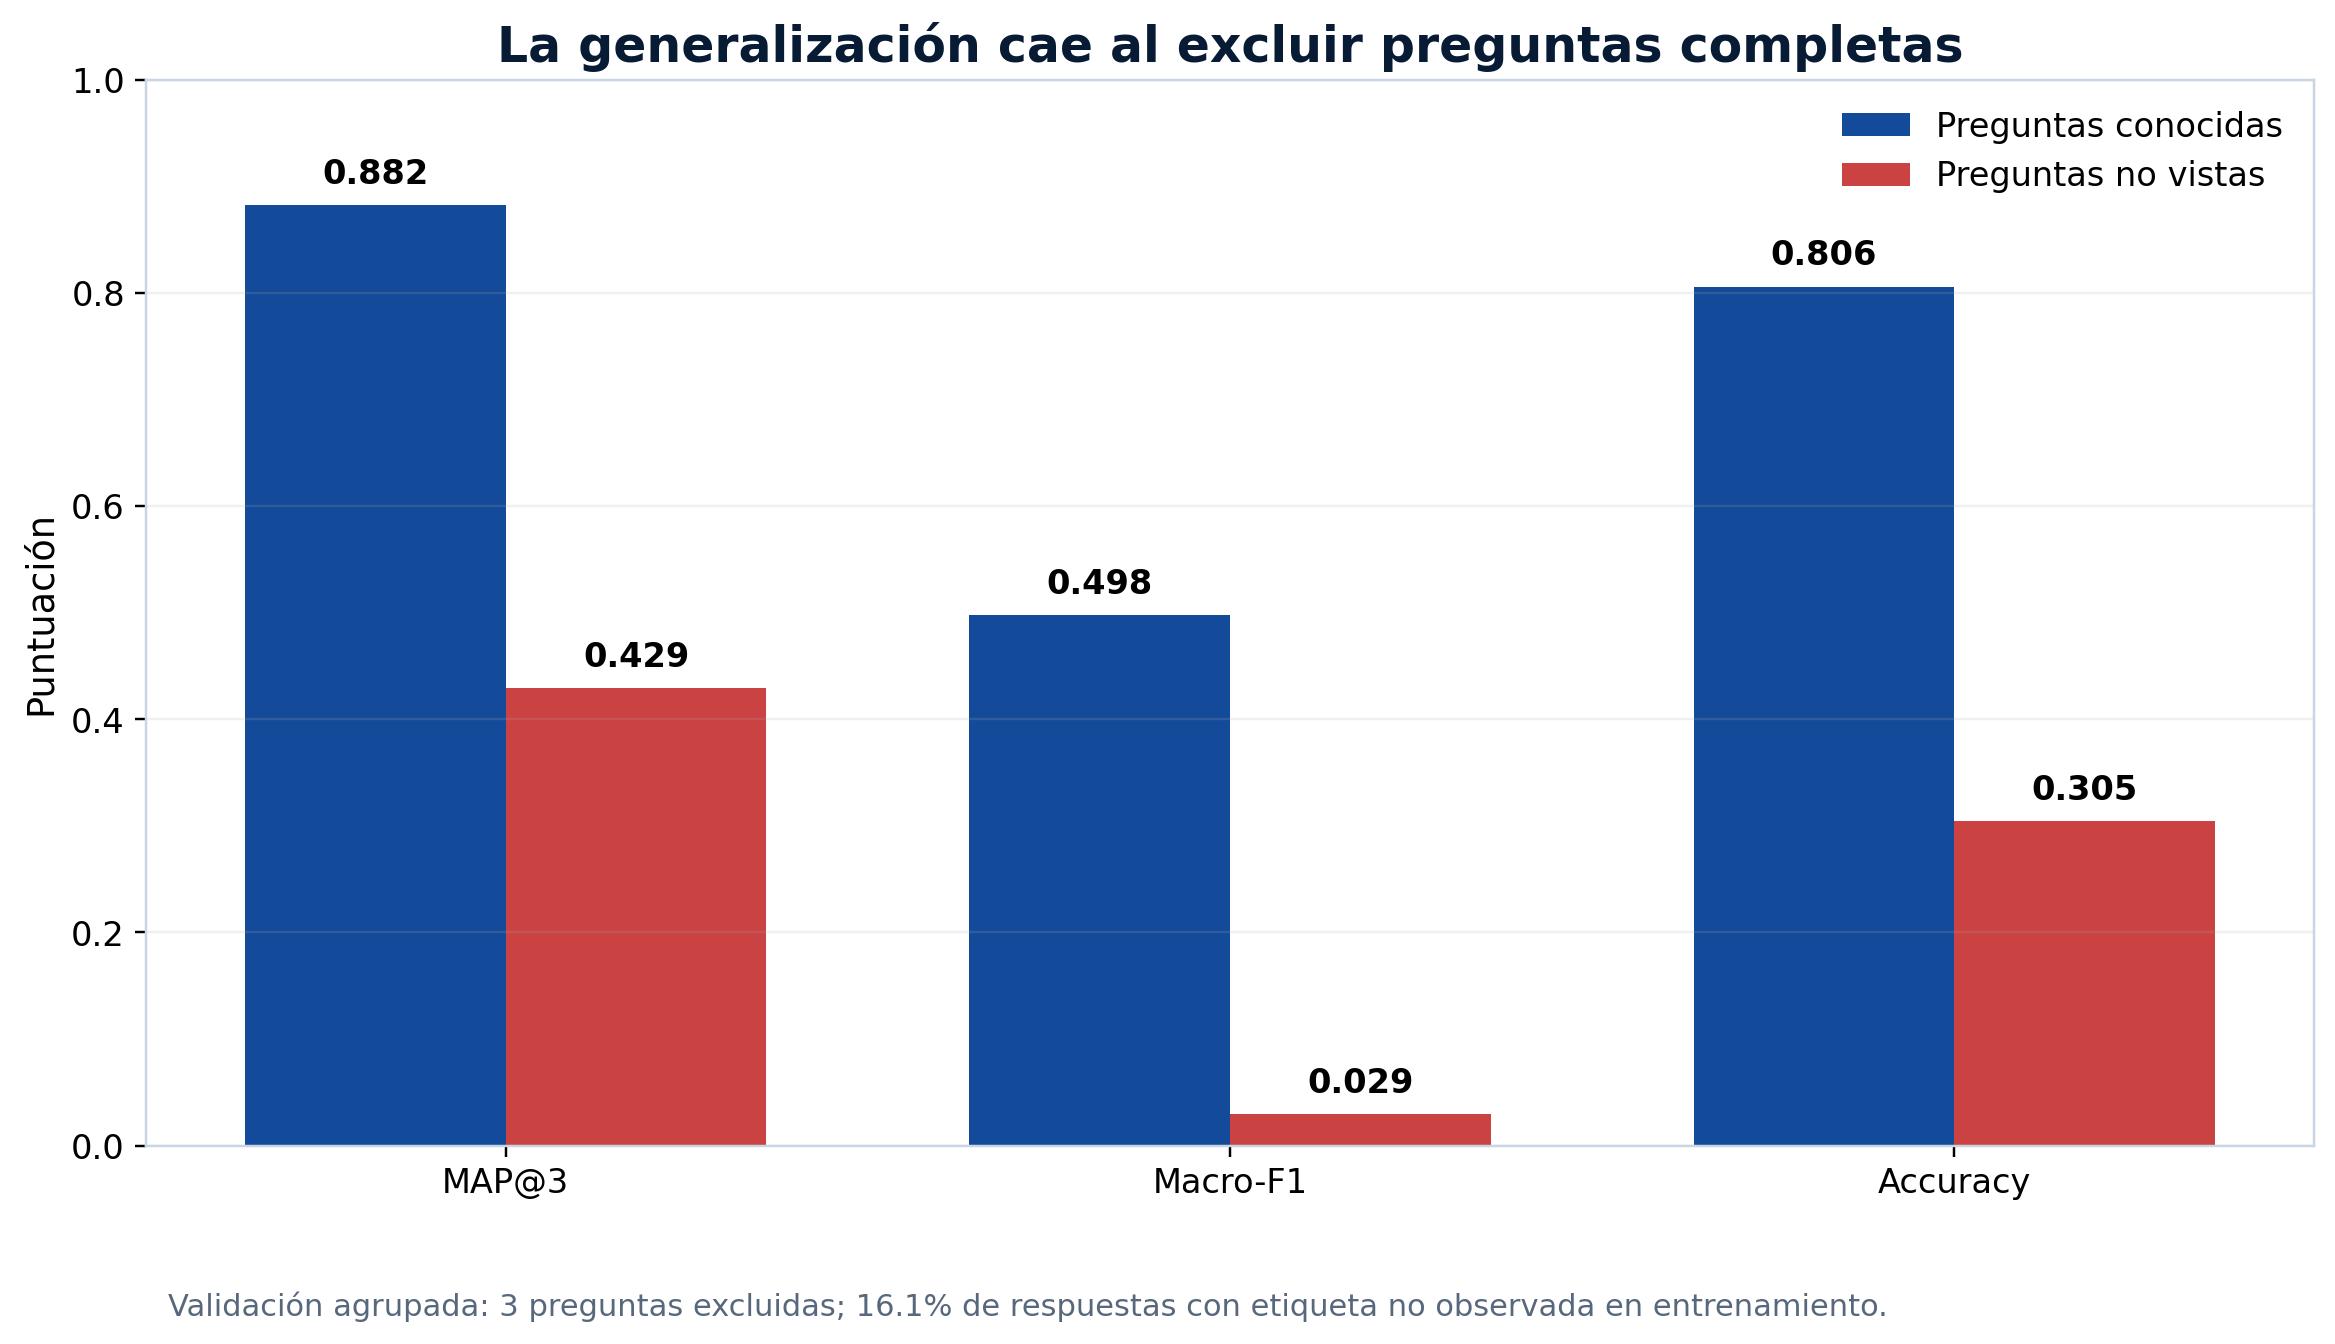

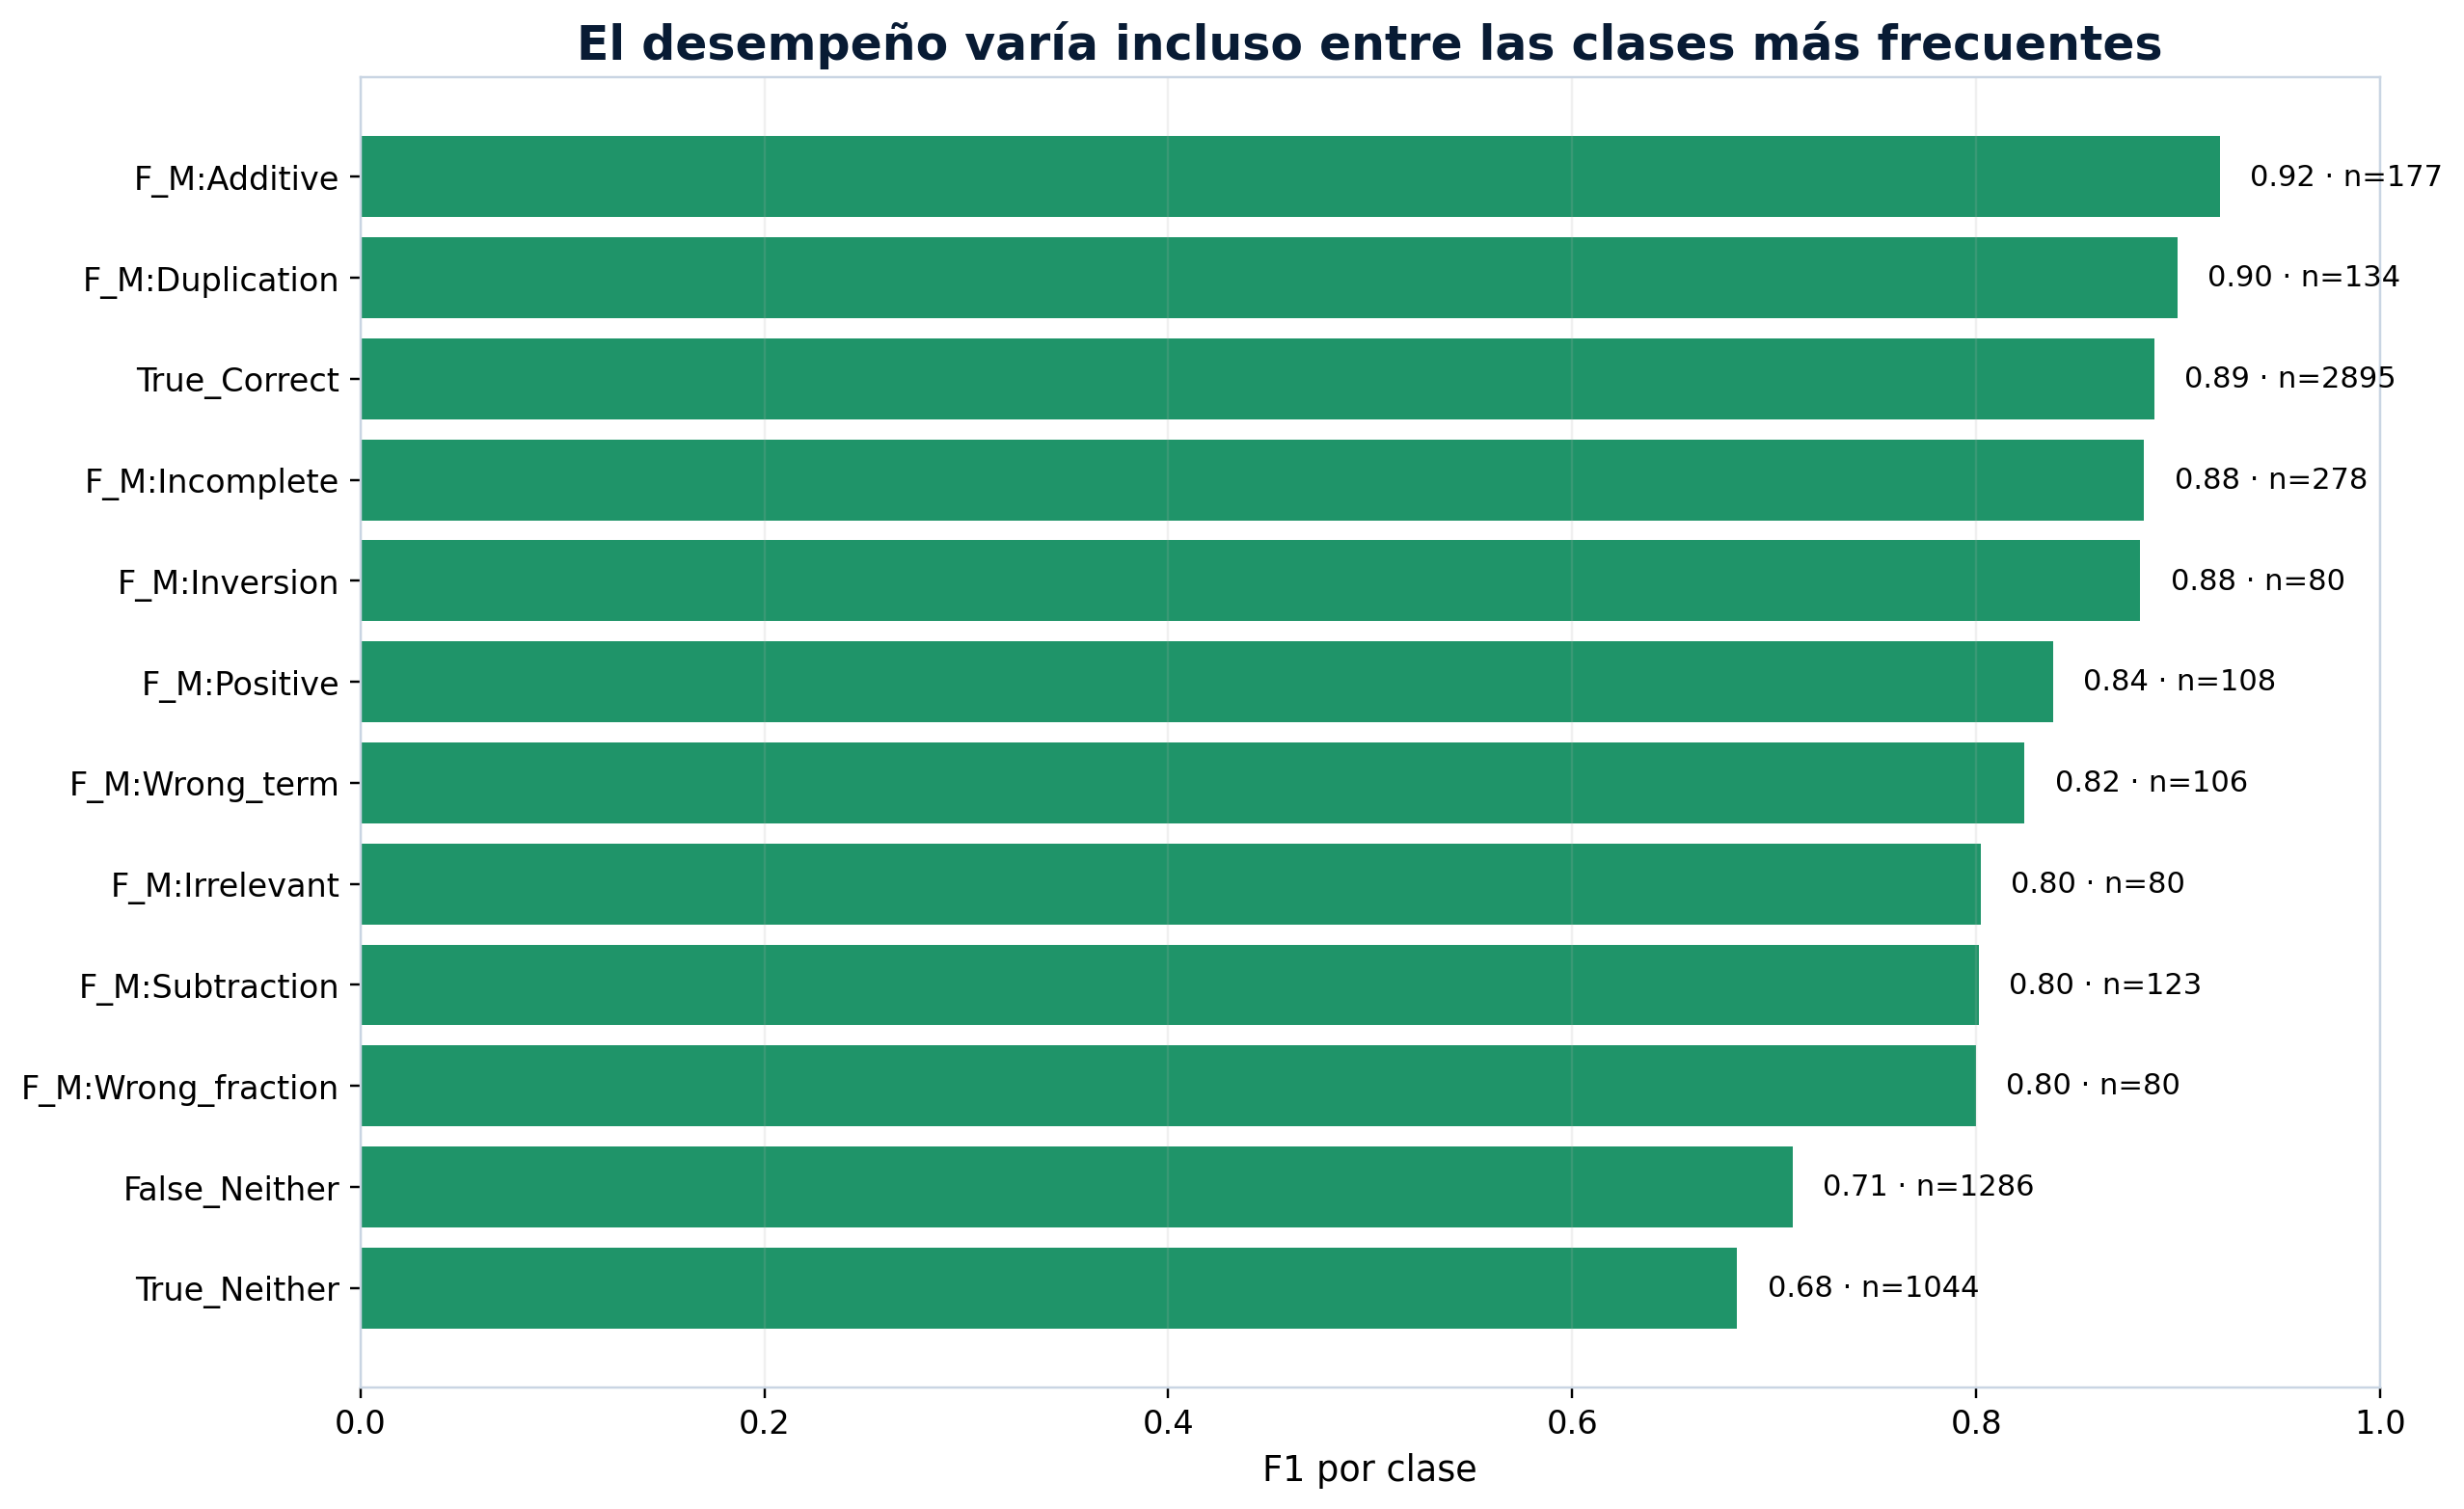

In [6]:
display(Image(filename=str(ASSETS / 'generalizacion_preguntas_no_vistas.png'), width=950))
display(Image(filename=str(ASSETS / 'f1_clases_frecuentes.png'), width=1050))

In [7]:
summary = json.loads((RESULTS / 'resumen_modelado.json').read_text(encoding='utf-8'))
summary

{'fecha_ejecucion': '2026-10-12T14:30:37.027401-06:00',
 'semilla': 42,
 'python': '3.13.1',
 'pandas': '2.2.3',
 'scikit_learn': '1.8.0',
 'filas_originales': 36696,
 'filas_modelado_sin_duplicados_exactos': 35960,
 'duplicados_exactos_retirados': 736,
 'n_clases': 65,
 'n_entrenamiento': 28769,
 'n_validacion': 7191,
 'n_caracteristicas_tfidf': 41763,
 'densidad_tfidf_pct': 0.708125211535505,
 'tiempo_vectorizacion_s': 26.541117399930954,
 'mejor_modelo': 'SVM lineal',
 'validacion_estratificada': {'modelo': 'SVM lineal',
  'map_at_3': 0.8823529411764706,
  'top3_accuracy': 0.968571825893478,
  'macro_f1': 0.49819214154420444,
  'accuracy': 0.8062856348213044,
  'tiempo_entrenamiento_s': 39.71736890007742,
  'n_clases_modelo': 65},
 'validacion_preguntas_no_vistas': {'modelo': 'SVM lineal',
  'map_at_3': 0.4293629786483148,
  'top3_accuracy': 0.5889888830068819,
  'macro_f1': 0.029301835123903514,
  'accuracy': 0.3046056114346215,
  'n_entrenamiento': 26515,
  'n_validacion': 9445,
 

## Decisión y limitaciones

- **Modelo seleccionado:** SVM lineal, por obtener el mayor MAP@3 y el mejor accuracy entre los baselines.
- **Resultado principal:** MAP@3 = 0.8824 y top-3 accuracy = 0.9686 en la validación estratificada.
- **Limitación:** al excluir preguntas completas, MAP@3 baja a 0.4294 y macro-F1 a 0.0293. Además, 16.1% de las respuestas de esa validación pertenecen a etiquetas no observadas durante el entrenamiento.
- **Interpretación:** el modelo es una línea base sólida para preguntas conocidas, pero no demuestra todavía generalización pedagógica suficiente a preguntas nuevas.
- **Siguiente paso:** evaluar Transformers contextuales, esquemas jerárquicos y aprendizaje de etiquetas raras con la misma partición agrupada.